# Battery Dispatch Optimizer

Portfolio analysis: wholesale day-ahead arbitrage for a simulated commercial battery
using German SMARD prices.

**Strategies compared**
1. Idle
2. Rule-based clock windows (charge 12–15h, discharge 18–21h)
3. Perfect-foresight MILP optimizer (CVXPY + HiGHS)

**Important limitations**
- Optimizer assumes perfect foresight of the full price path — benchmark only, not a deployable trading policy.
- Value is wholesale arbitrage EUR, not customer bill savings.
- Excludes grid fees, taxes, degradation, imbalance, and retail tariffs.

## 0. Setup

In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt

# Allow running the notebook from notebooks/ or repo root
REPO = Path.cwd()
if not (REPO / "src").exists():
    REPO = REPO.parent
sys.path.insert(0, str(REPO))

from src.data_loader import load_clean_prices
from src.battery import DEFAULT_BATTERY, BatteryParams
from src.optimizer import optimize_dispatch
from src.strategies import idle_strategy, clock_window_strategy
from src.evaluation import evaluate_schedule, comparison_table
from src.visualization import (
    plot_price_timeseries,
    plot_price_by_hour_of_day,
    plot_price_by_day_of_week,
    plot_price_hour_dow_heatmap,
    plot_dispatch_timeseries,
    plot_dispatch_zoom,
    plot_strategy_arbitrage_comparison,
    plot_cumulative_arbitrage,
    plot_efficiency_sensitivity,
    generate_price_eda_figures,
)

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
print("repo:", REPO)
print("battery:", DEFAULT_BATTERY)

repo: /home/gatemrou/uds/battery-dispatch-optimizer
battery: BatteryParams(capacity_kwh=100.0, max_charge_kw=50.0, max_discharge_kw=50.0, charge_efficiency=0.95, discharge_efficiency=0.95, initial_soc_frac=0.5, final_soc_frac=0.5, dt_hours=1.0)


## 1. Data load and validation

SMARD day-ahead prices for DE, stored in `data/raw/prices-de-aug-oct.csv`.
Cleaning rules (no fabricated fills): parse timestamps, enforce 1h intervals,
average the DST fall-back duplicate hour, convert EUR/MWh → EUR/kWh.

In [2]:
prices, report = load_clean_prices()
display(pd.Series(report, dtype=object))
display(prices.head())
print(prices["price_eur_per_mwh"].describe())

n_raw_rows                                                                    1489
issues                           [duplicate_start_timestamps=1 affecting_rows=2...
actions                          [averaged_duplicate_wall_clock_hours=1; DST fa...
n_non_hourly_gaps_after_clean                                                    0
n_clean_rows                                                                  1488
timestamp_min                                                  2026-08-28 00:00:00
timestamp_max                                                  2026-10-28 23:00:00
price_eur_per_mwh_min                                                     -19.0000
price_eur_per_mwh_max                                                     697.3100
price_eur_per_mwh_mean                                                    148.0884
n_negative_prices                                                               56
n_missing_prices                                                                 0
unit

,timestamp,timestamp_end,price_eur_per_mwh,price_eur_per_kwh
0,2026-08-28 00:00:00,2026-08-28 01:00:00,139.5200,0.1395
1,2026-08-28 01:00:00,2026-08-28 02:00:00,139.2900,0.1393
2,2026-08-28 02:00:00,2026-08-28 03:00:00,138.2400,0.1382
3,2026-08-28 03:00:00,2026-08-28 04:00:00,138.8000,0.1388
4,2026-08-28 04:00:00,2026-08-28 05:00:00,139.0900,0.1391


count   1,488.0000
mean      148.0884
std        79.1685
min       -19.0000
25%       102.0025
50%       160.2750
75%       196.6175
max       697.3100
Name: price_eur_per_mwh, dtype: float64


## 2. Price exploratory plots

reports/figures/01_price_timeseries.png
reports/figures/02_price_by_hour_of_day.png
reports/figures/03_price_by_day_of_week.png
reports/figures/04_price_hour_dow_heatmap.png
reports/figures/05_daily_mean_price.png


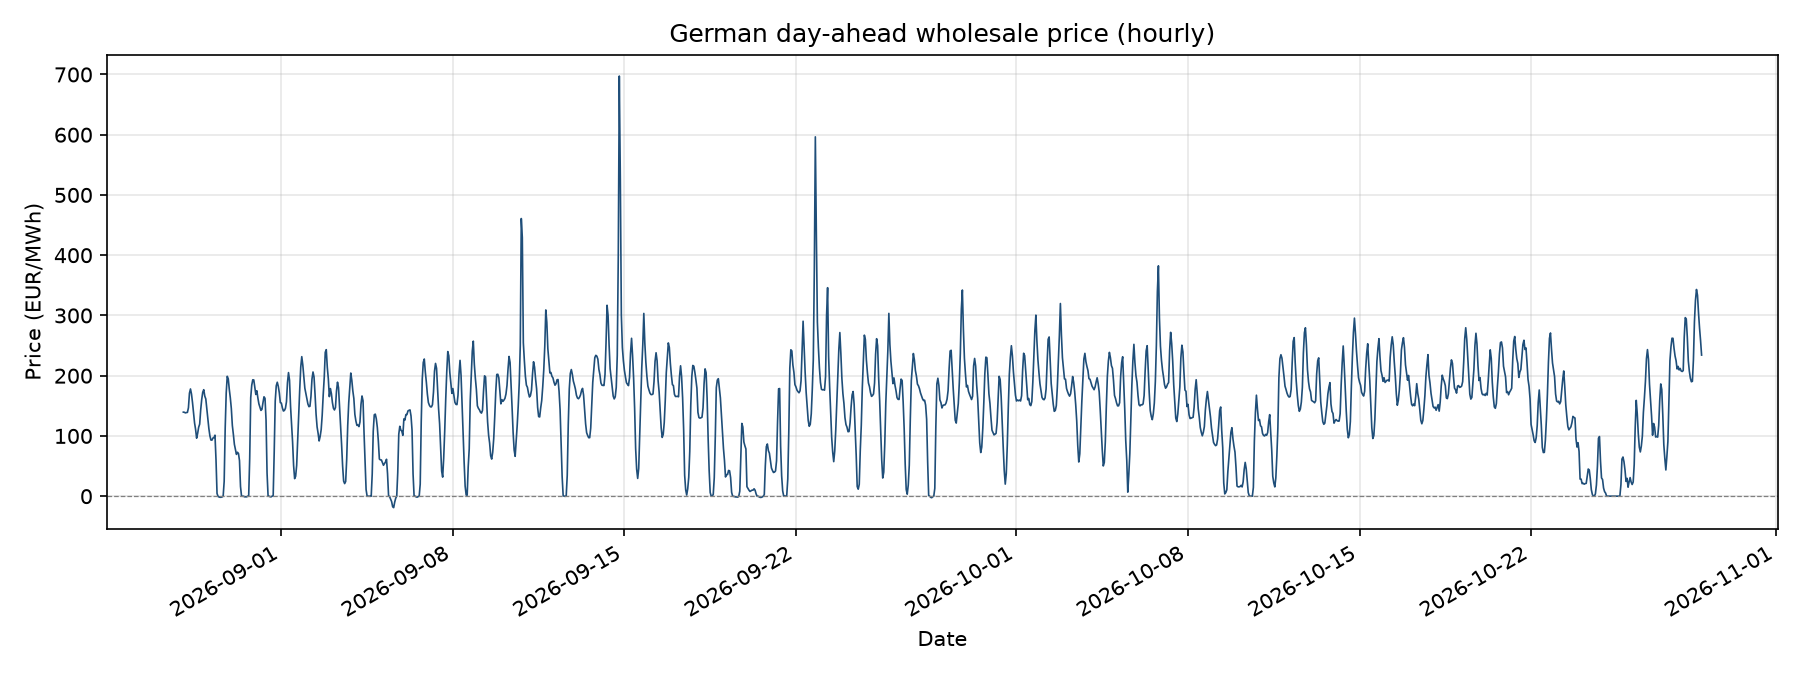

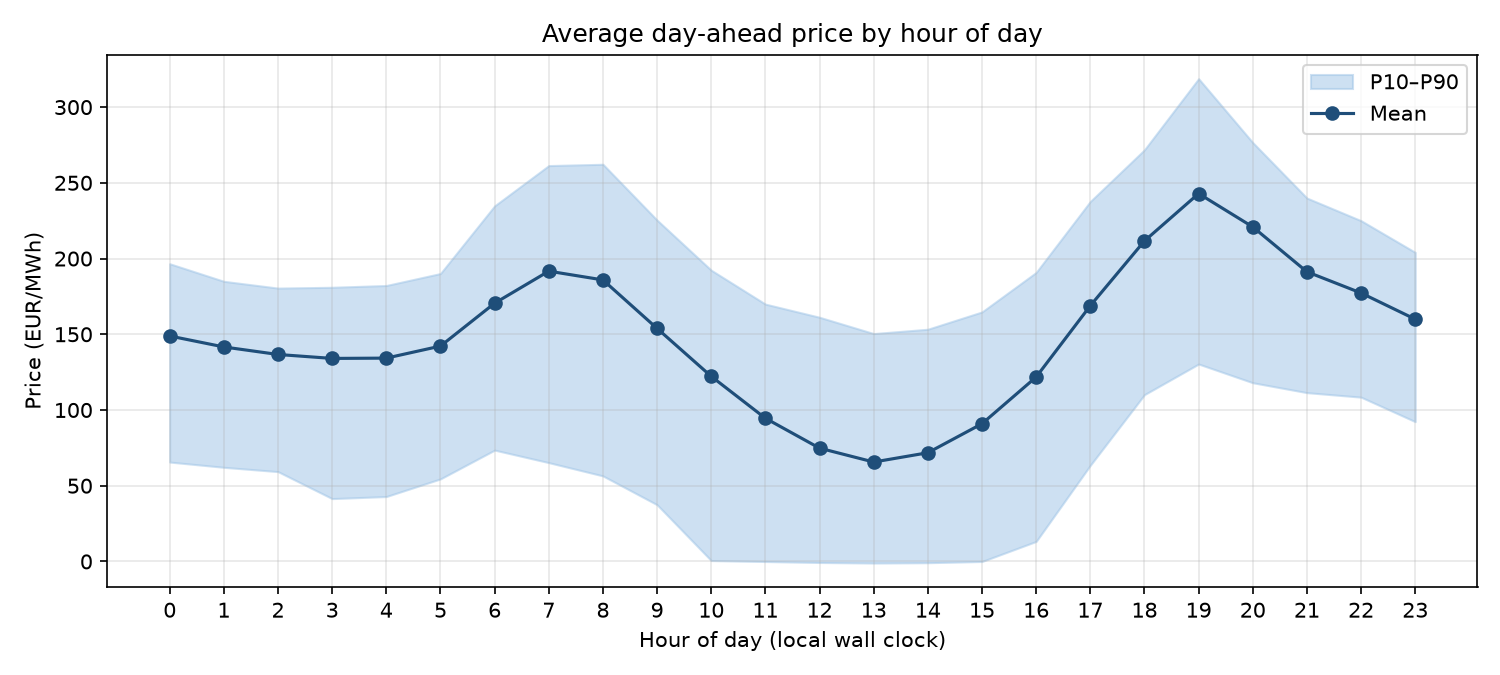

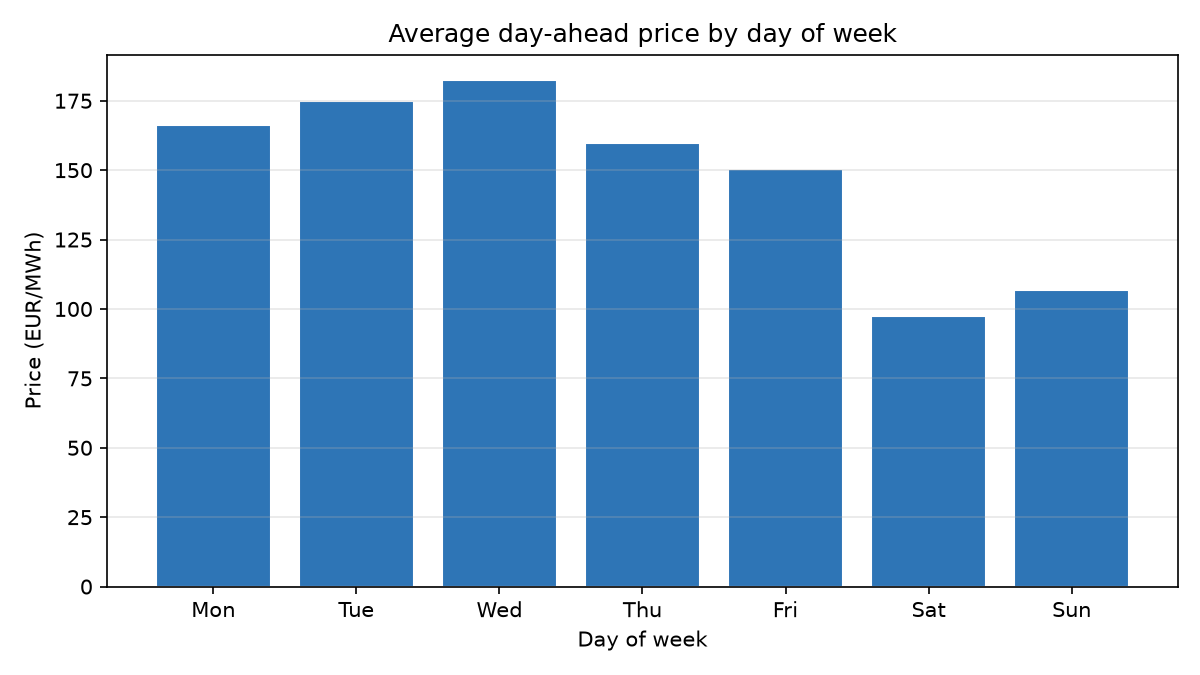

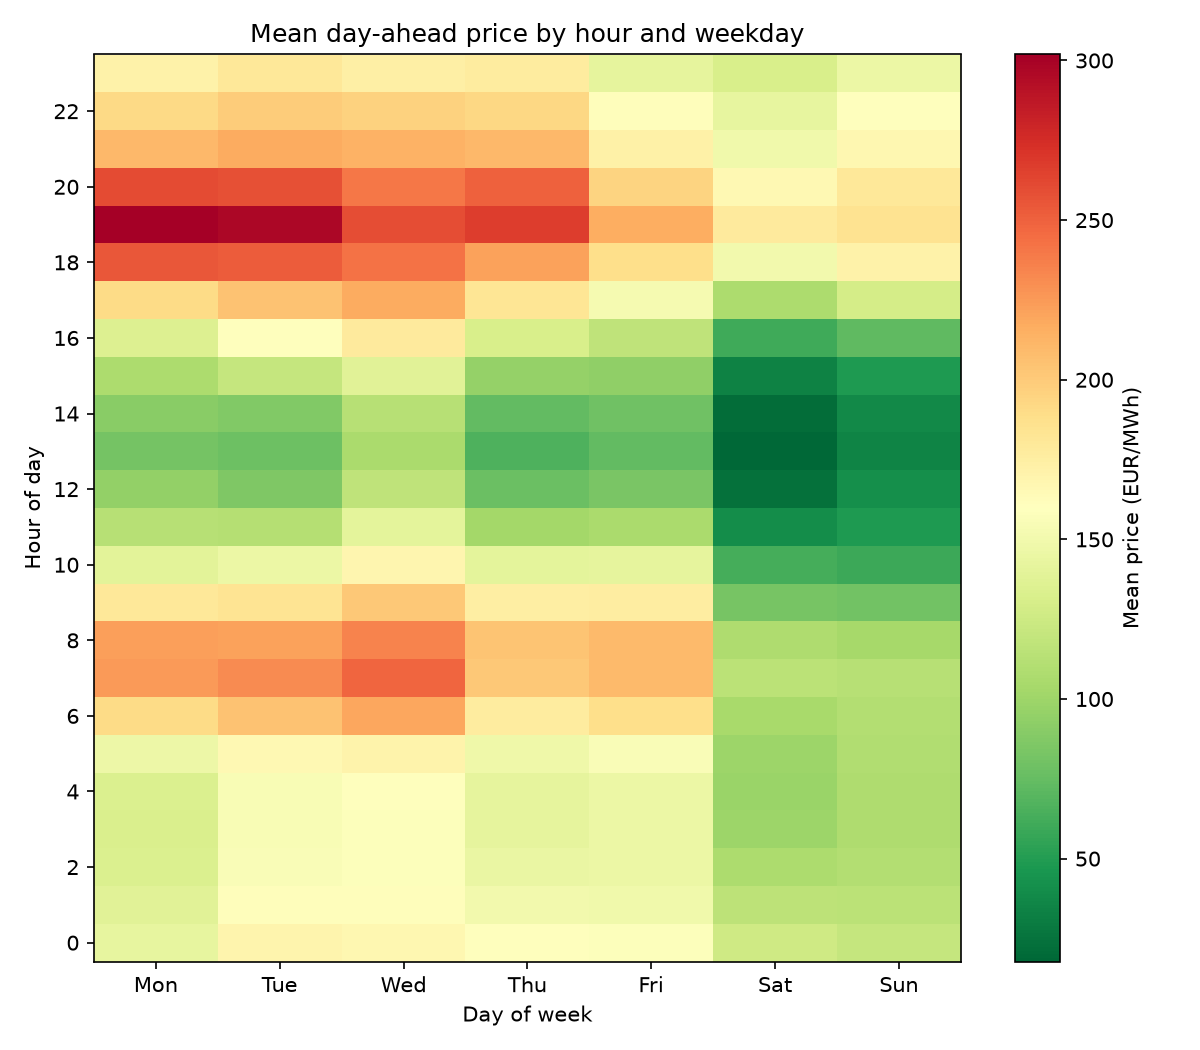

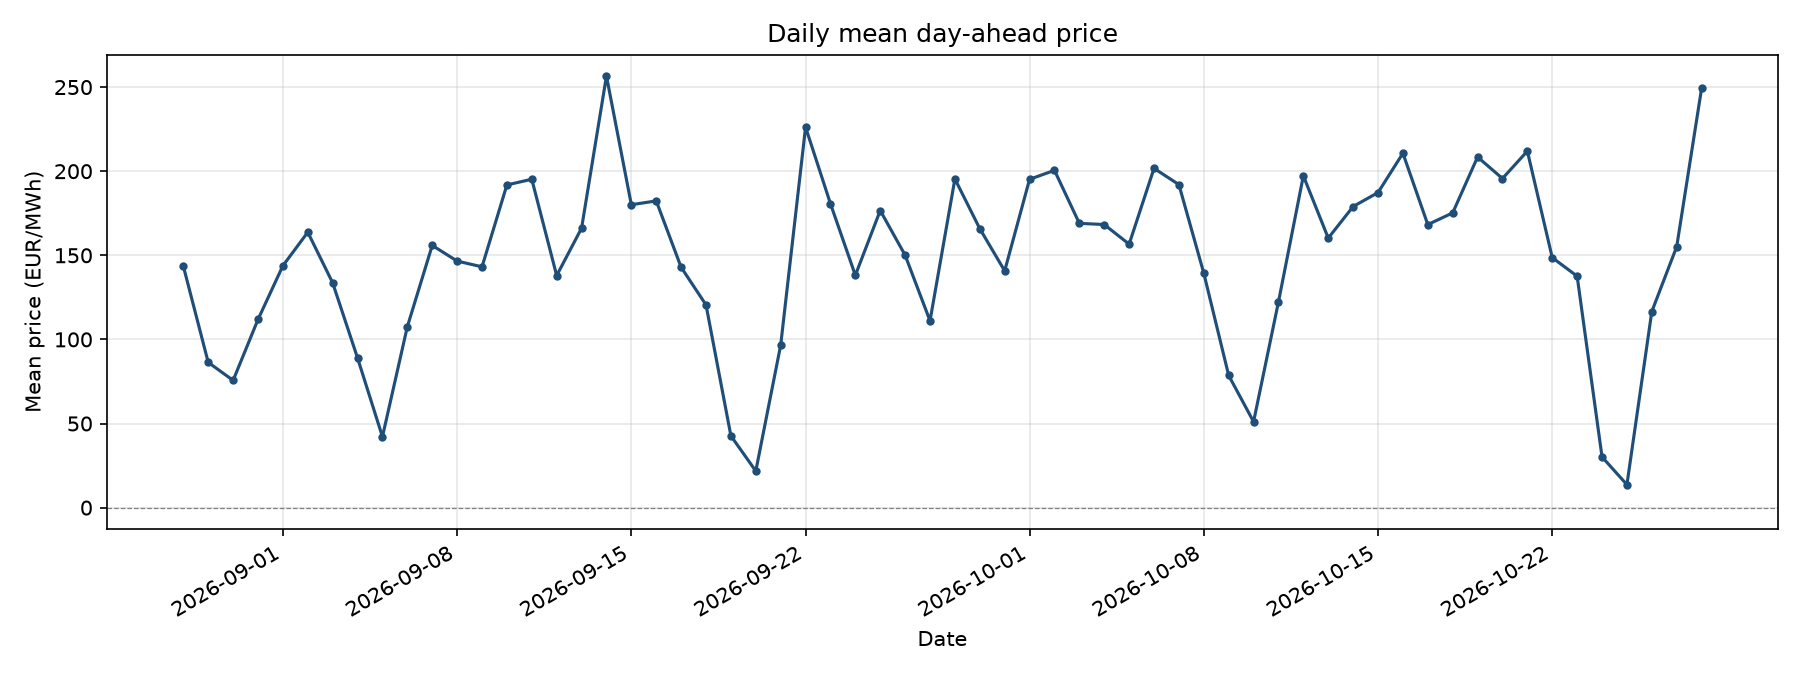

In [3]:
fig_dir = REPO / "reports" / "figures"
paths = generate_price_eda_figures(prices, fig_dir=fig_dir)
for p in paths:
    print(p.relative_to(REPO))

from IPython.display import Image, display
for name in [
    "01_price_timeseries.png",
    "02_price_by_hour_of_day.png",
    "03_price_by_day_of_week.png",
    "04_price_hour_dow_heatmap.png",
    "05_daily_mean_price.png",
]:
    display(Image(filename=str(fig_dir / name)))

## 3. Battery assumptions

| Parameter | Value |
|-----------|-------|
| Capacity | 100 kWh |
| Max charge / discharge | 50 kW |
| η charge / discharge | 95% |
| Initial = final SOC | 50% |
| Δt | 1 h |

In [4]:
batt = DEFAULT_BATTERY
batt.to_dict()

{'capacity_kwh': 100.0,
 'max_charge_kw': 50.0,
 'max_discharge_kw': 50.0,
 'charge_efficiency': 0.95,
 'discharge_efficiency': 0.95,
 'initial_soc_frac': 0.5,
 'final_soc_frac': 0.5,
 'dt_hours': 1.0,
 'initial_soc_kwh': 50.0,
 'final_soc_kwh': 50.0,
 'max_charge_kwh': 50.0,
 'max_discharge_kwh': 50.0,
 'round_trip_efficiency': 0.9025}

## 4. Strategies

### Idle
No charge/discharge. Arbitrage = 0.

### Clock-window rule
- Charge hours: 12, 13, 14, 15 (midday trough from EDA)
- Discharge hours: 18, 19, 20, 21 (evening peak)
- Respects power, SOC, efficiencies; repairs terminal SOC to 50 kWh

### Optimized MILP
Maximize `sum p_t * (discharge_t - charge_t)` with SOC dynamics, power limits,
SOC bounds, fixed start/end SOC, and binary mode variables banning simultaneous
charge and discharge. Solved with HiGHS over the **full** horizon (perfect foresight).

In [5]:
idle = idle_strategy(prices, batt)
rule = clock_window_strategy(prices, batt)
opt = optimize_dispatch(prices, batt)
print("optimizer status:", opt.status, "objective EUR:", round(opt.objective_value, 2))
opt.schedule.head()

optimizer status: optimal objective EUR: 1233.67


,timestamp,timestamp_end,price_eur_per_kwh,price_eur_per_mwh,charge_kwh,discharge_kwh,soc_start_kwh,soc_end_kwh,is_charging_mode,arbitrage_eur
0,2026-08-28 00:00:00,2026-08-28 01:00:00,0.1395,139.5200,0.0000,0.0000,50.0000,50.0000,False,0.0000
1,2026-08-28 01:00:00,2026-08-28 02:00:00,0.1393,139.2900,0.0000,0.0000,50.0000,50.0000,False,0.0000
2,2026-08-28 02:00:00,2026-08-28 03:00:00,0.1382,138.2400,50.0000,0.0000,50.0000,97.5000,True,-6.9120
3,2026-08-28 03:00:00,2026-08-28 04:00:00,0.1388,138.8000,2.6316,0.0000,97.5000,100.0000,True,-0.3653
4,2026-08-28 04:00:00,2026-08-28 05:00:00,0.1391,139.0900,0.0000,0.0000,100.0000,100.0000,False,0.0000


## 5. Evaluation

In [6]:
metrics = [
    evaluate_schedule(idle, batt, strategy_name="idle"),
    evaluate_schedule(rule, batt, strategy_name="clock_window"),
    evaluate_schedule(opt.schedule, batt, strategy_name="optimized"),
]
table = comparison_table(metrics)
display(table)
display(pd.DataFrame(metrics)[["strategy", "feasible", "soc_min_kwh", "soc_max_kwh", "soc_final_kwh"]])
for m in metrics:
    print(m["strategy"], "violations:", m["violations"])

,strategy,arbitrage_eur,eur_per_kwh_cap,charge_kwh,discharge_kwh,full_cycles,hours_chg,hours_dis,soc_min,soc_max,feasible,improvement_vs_rule_eur,improvement_vs_rule_pct
0,idle,0.0000,0.0000,0.0000,0.0000,0.0000,0,0,50.0000,50.0000,True,-864.2043,-100.0000
1,clock_window,864.2043,8.6420,"6,473.6842","5,842.5000",61.5000,185,123,0.0000,100.0000,True,0.0000,0.0000
2,optimized,"1,233.6690",12.3367,"12,500.2770","11,281.5000",118.7526,353,238,-0.0000,100.0000,True,369.4648,42.7520


,strategy,feasible,soc_min_kwh,soc_max_kwh,soc_final_kwh
0,idle,True,50.0000,50.0000,50.0000
1,clock_window,True,0.0000,100.0000,50.0000
2,optimized,True,-0.0000,100.0000,50.0000


idle violations: {'soc_below_zero': 0, 'soc_above_capacity': 0, 'charge_above_power': 0, 'discharge_above_power': 0, 'simultaneous_charge_discharge': 0, 'initial_soc_mismatch': 0.0, 'final_soc_mismatch': 0.0, 'soc_dynamics_mismatch_max': 0.0, 'n_constraint_violations': 0}
clock_window violations: {'soc_below_zero': 0, 'soc_above_capacity': 0, 'charge_above_power': 0, 'discharge_above_power': 0, 'simultaneous_charge_discharge': 0, 'initial_soc_mismatch': 0.0, 'final_soc_mismatch': 0.0, 'soc_dynamics_mismatch_max': 0.0, 'n_constraint_violations': 0}
optimized violations: {'soc_below_zero': 0, 'soc_above_capacity': 0, 'charge_above_power': 0, 'discharge_above_power': 0, 'simultaneous_charge_discharge': 0, 'initial_soc_mismatch': 0.0, 'final_soc_mismatch': 1.5631940186722204e-12, 'soc_dynamics_mismatch_max': 1.5631940186722204e-12, 'n_constraint_violations': 0}


## 6. Dispatch and comparison figures

/tmp/ipykernel_42500/801131114.py:5: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  zoom_start = mid.normalize() - pd.Timedelta(days=int(mid.dayofweek))


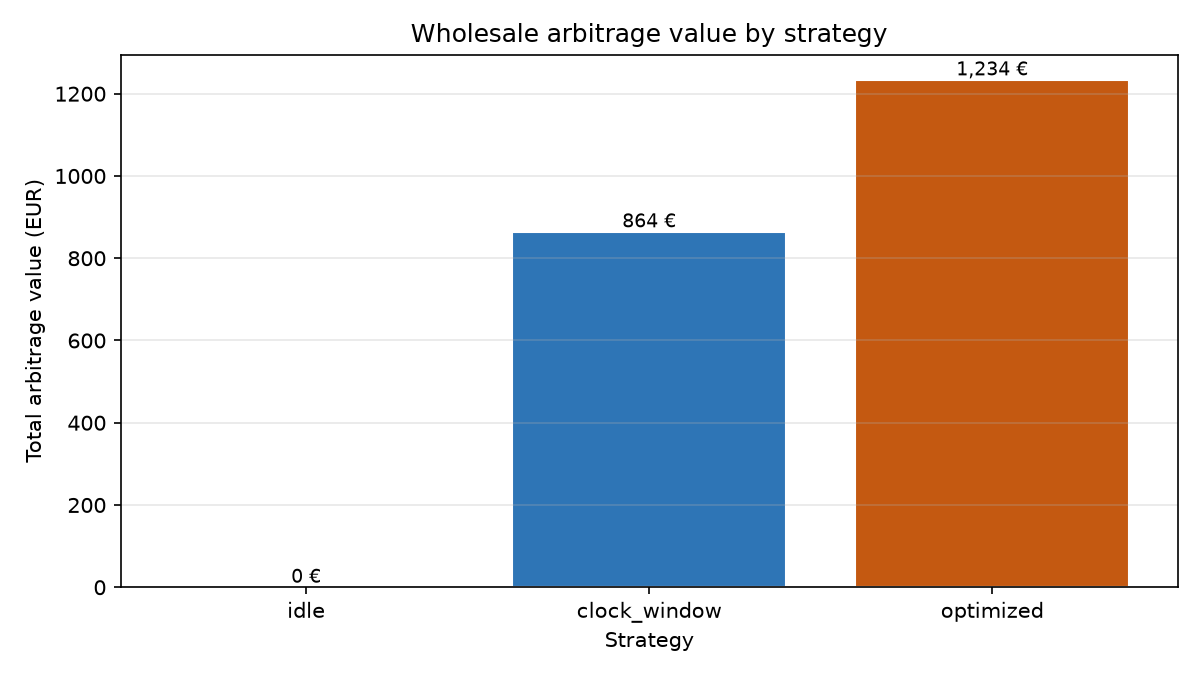

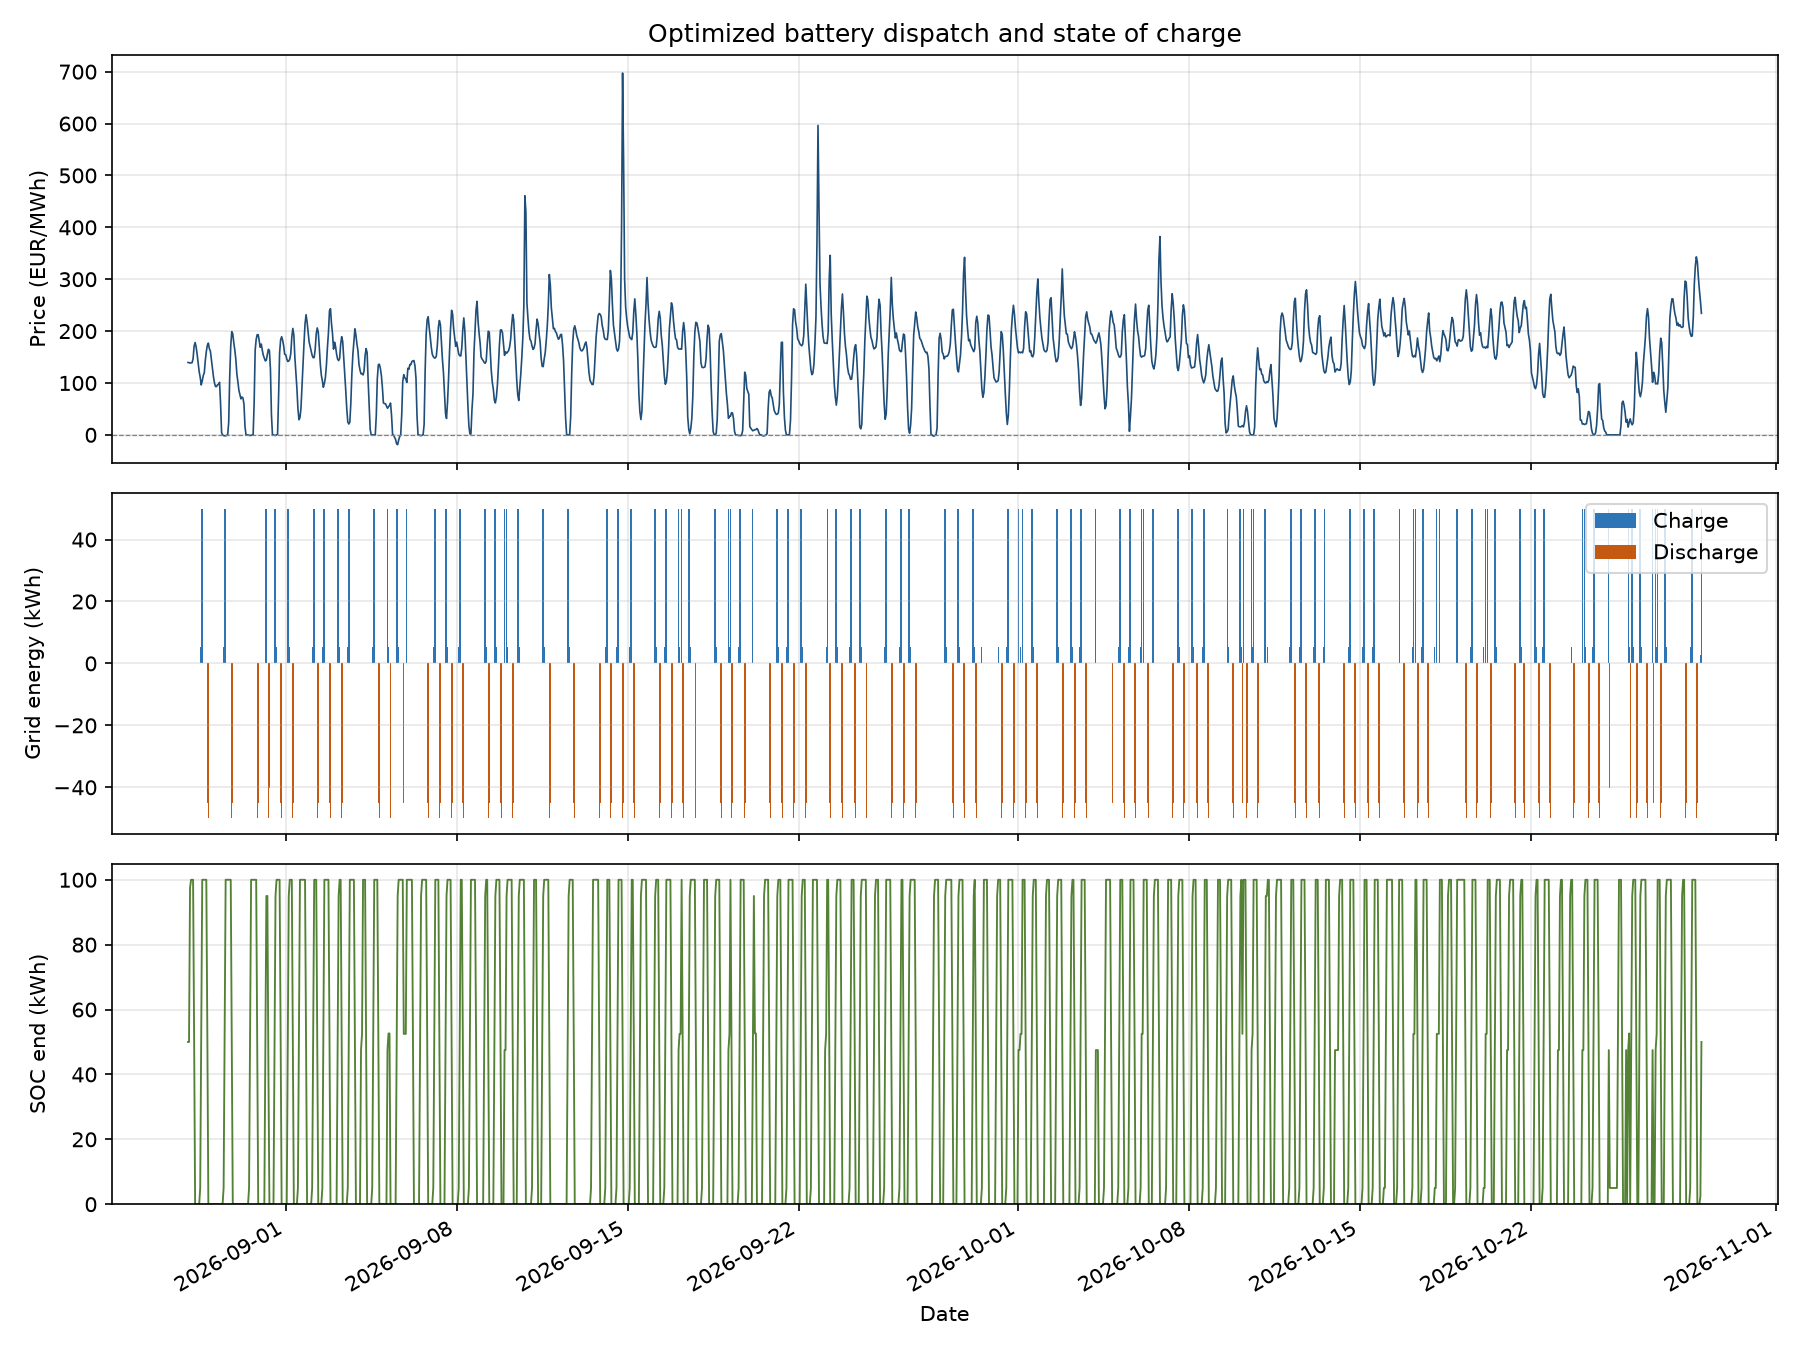

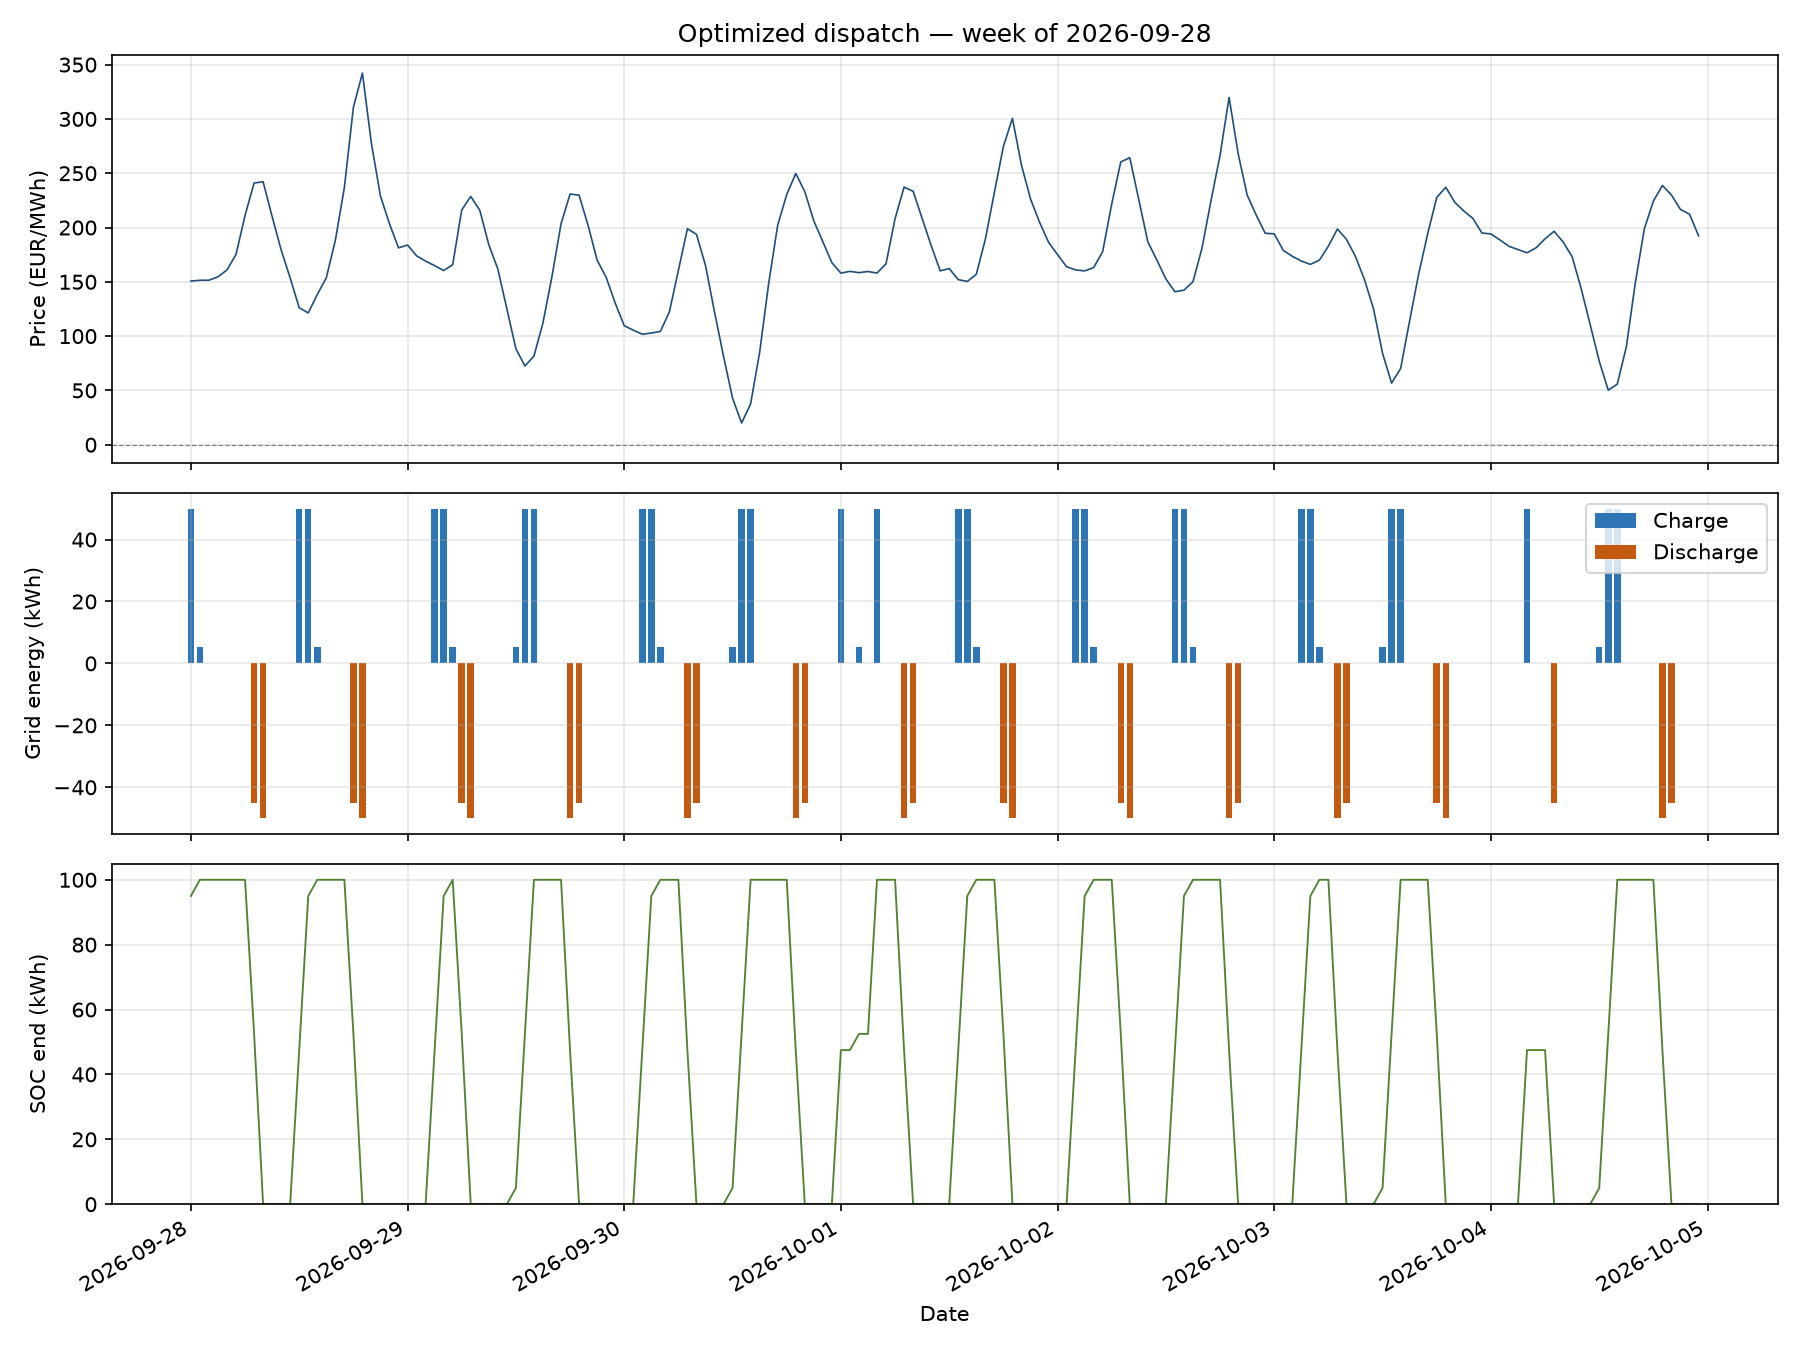

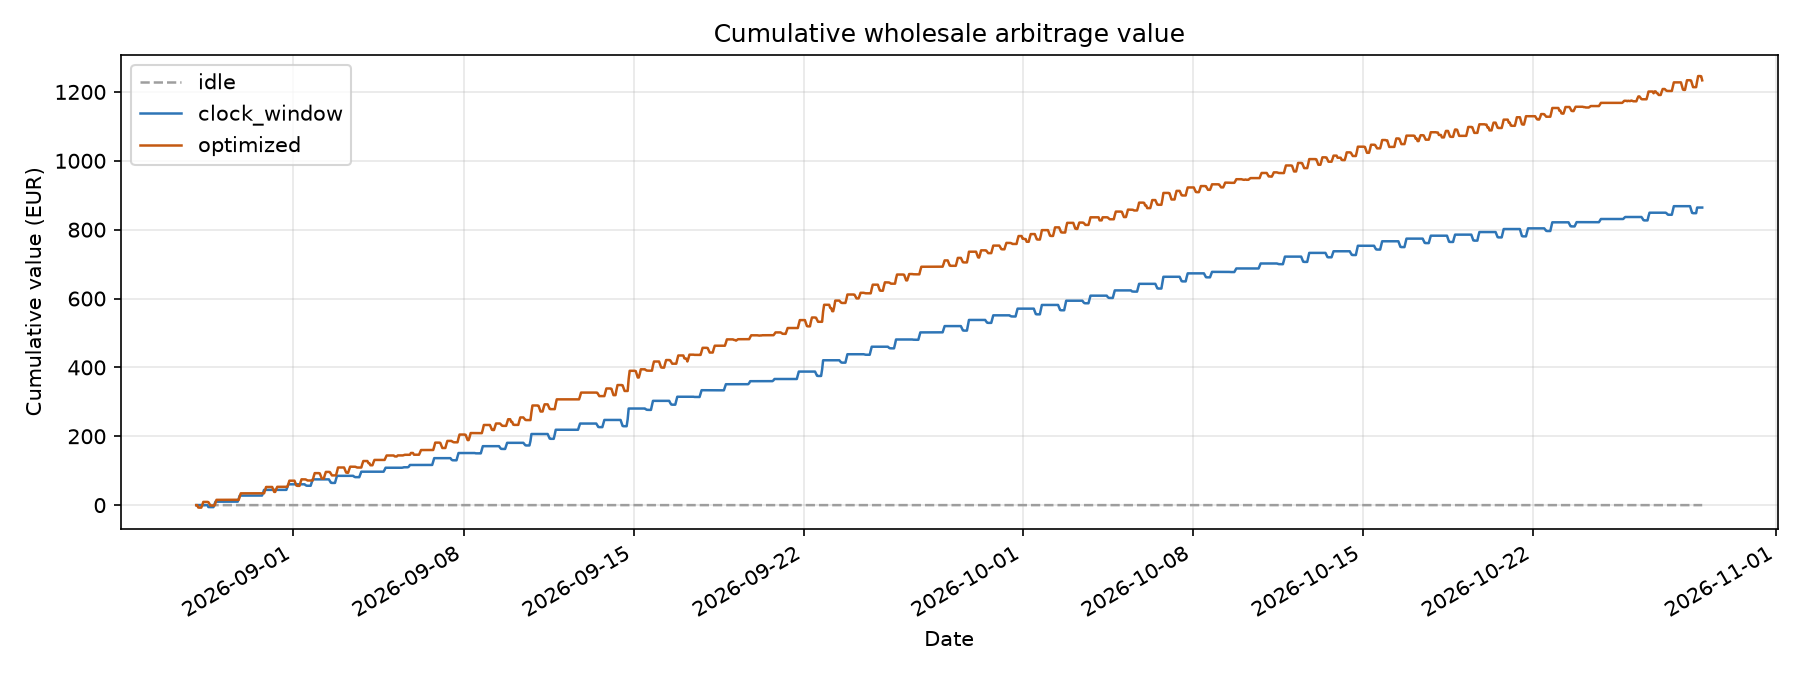

In [7]:
plot_strategy_arbitrage_comparison(table, fig_dir=fig_dir)
plot_dispatch_timeseries(opt.schedule, fig_dir=fig_dir, filename="07_optimized_dispatch.png")

mid = pd.Timestamp(prices["timestamp"].iloc[len(prices) // 2])
zoom_start = mid.normalize() - pd.Timedelta(days=int(mid.dayofweek))
zoom_end = zoom_start + pd.Timedelta(days=7)
plot_dispatch_zoom(
    opt.schedule,
    start=zoom_start,
    end=zoom_end,
    fig_dir=fig_dir,
    filename="08_optimized_dispatch_zoom.png",
    title=f"Optimized dispatch — week of {zoom_start.date()}",
)
plot_cumulative_arbitrage(
    {"idle": idle, "clock_window": rule, "optimized": opt.schedule},
    fig_dir=fig_dir,
)

for name in [
    "06_strategy_arbitrage_comparison.png",
    "07_optimized_dispatch.png",
    "08_optimized_dispatch_zoom.png",
    "09_cumulative_arbitrage.png",
]:
    display(Image(filename=str(fig_dir / name)))

## 7. Sensitivity — efficiency

Re-solve the full-horizon MILP with η_c = η_d ∈ {0.85, 0.90, 0.95, 0.98, 1.00}.
Higher efficiency → more cycles and higher arbitrage (round-trip losses shrink).

η=0.85 → 873.16 EUR
η=0.90 → 1,043.42 EUR
η=0.95 → 1,233.67 EUR
η=0.98 → 1,350.27 EUR
η=1.00 → 1,432.79 EUR


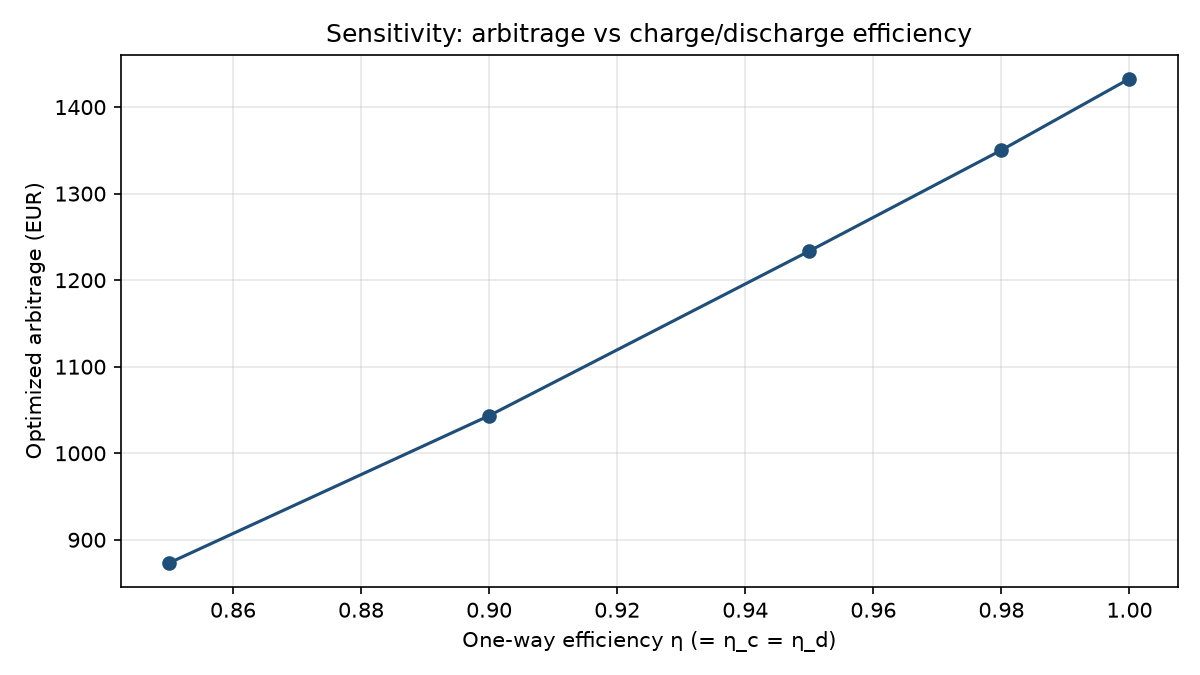

,efficiency,arbitrage_eur
0,0.8500,873.1640
1,0.9000,"1,043.4249"
2,0.9500,"1,233.6690"
3,0.9800,"1,350.2717"
4,1.0000,"1,432.7905"


In [8]:
etas = [0.85, 0.90, 0.95, 0.98, 1.00]
rows = []
for eta in etas:
    b = BatteryParams(charge_efficiency=eta, discharge_efficiency=eta)
    r = optimize_dispatch(prices, b)
    rows.append({"efficiency": eta, "arbitrage_eur": r.objective_value})
    print(f"η={eta:.2f} → {r.objective_value:,.2f} EUR")
sens = pd.DataFrame(rows)
sens.to_csv(REPO / "reports" / "sensitivity_efficiency.csv", index=False)
plot_efficiency_sensitivity(sens, fig_dir=fig_dir)
display(Image(filename=str(fig_dir / "10_sensitivity_efficiency.png")))
sens

## 8. Takeaways

- Strong diurnal spread (midday low, evening high) drives value.
- Clock windows capture a large share of available arbitrage with a simple rule.
- Perfect-foresight MILP improves further by using atypical spikes/negatives and multi-cycle days.
- Results are **not** customer savings or realized trading profit.

Figures also live under `reports/figures/` for the written report.

## 9. More realistic strategies (hold-out)

Full-horizon perfect foresight is an **upper bound**, not a policy.

**Hold-out protocol**
- Split by calendar day at 50% of days.
- Warm-up (first half): history only for forecasts.
- Test (second half): score all strategies on the same window.

**New strategies**
1. **Day-ahead rolling MILP** — each day optimize only that day's actual DA prices; SOC carries overnight; free EOD SOC except final day (=50%).
2. **Forecast → optimize** — seasonal-naive forecast = mean of last 7 days' same clock-hour; MILP on forecast; P&L on actual; no leakage of future actuals into the plan.

n_days_total                     62
n_days_warm                      31
n_days_test                      31
warm_start      2026-08-28 00:00:00
warm_end        2026-09-27 23:00:00
test_start      2026-09-28 00:00:00
test_end        2026-10-28 23:00:00
frac                         0.5000
dtype: object

,strategy,arbitrage_eur,eur_per_kwh_cap,charge_kwh,discharge_kwh,full_cycles,hours_chg,hours_dis,soc_min,soc_max,feasible,improvement_vs_rule_eur,improvement_vs_rule_pct
0,idle,0.0000,0.0000,0.0000,0.0000,0.0000,0,0,50.0000,50.0000,True,-350.7219,-100.0000
1,clock_window,350.7219,3.5072,"3,210.5263","2,897.5000",30.5000,92,61,0.0000,100.0000,True,0.0000,0.0000
2,optimized_full_test,530.6927,5.3069,"6,621.1911","5,975.6250",62.9013,188,126,-0.0000,100.0000,True,179.9708,51.3144
3,day_ahead_rolling,528.9353,5.2894,"6,515.7895","5,880.5000",61.9000,185,124,-0.0000,100.0000,True,178.2134,50.8133
4,forecast_optimize,505.4562,5.0546,"6,573.6842","5,932.7500",62.4500,187,125,-0.0000,100.0000,True,154.7344,44.1188


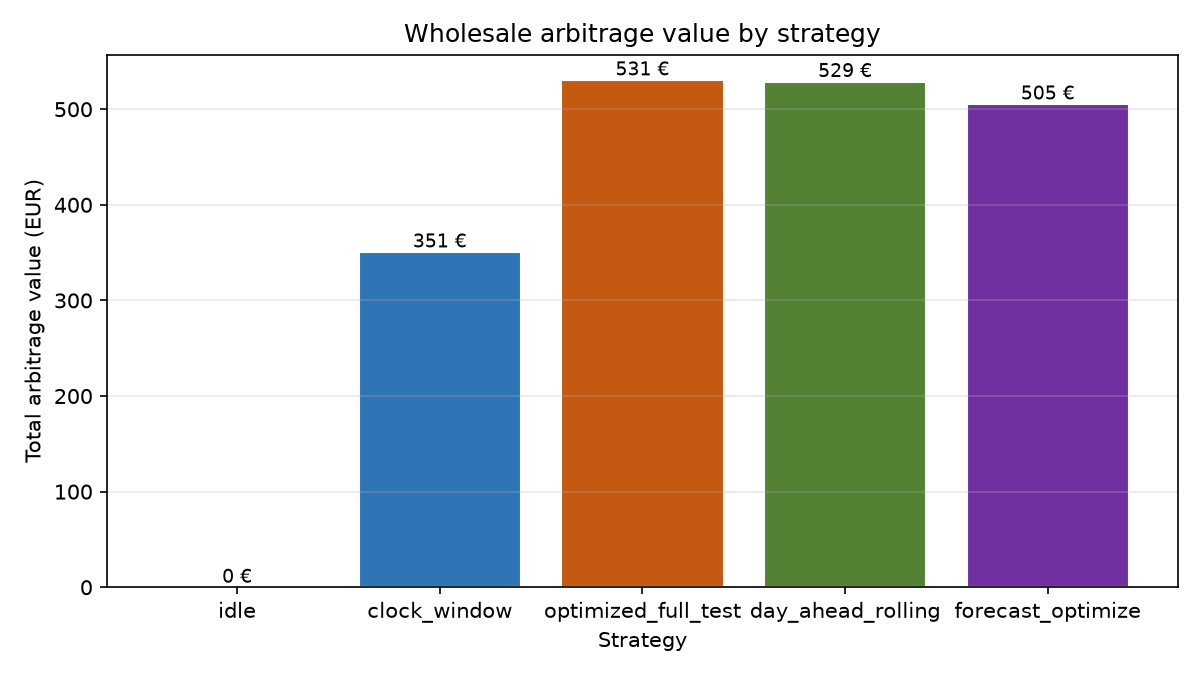

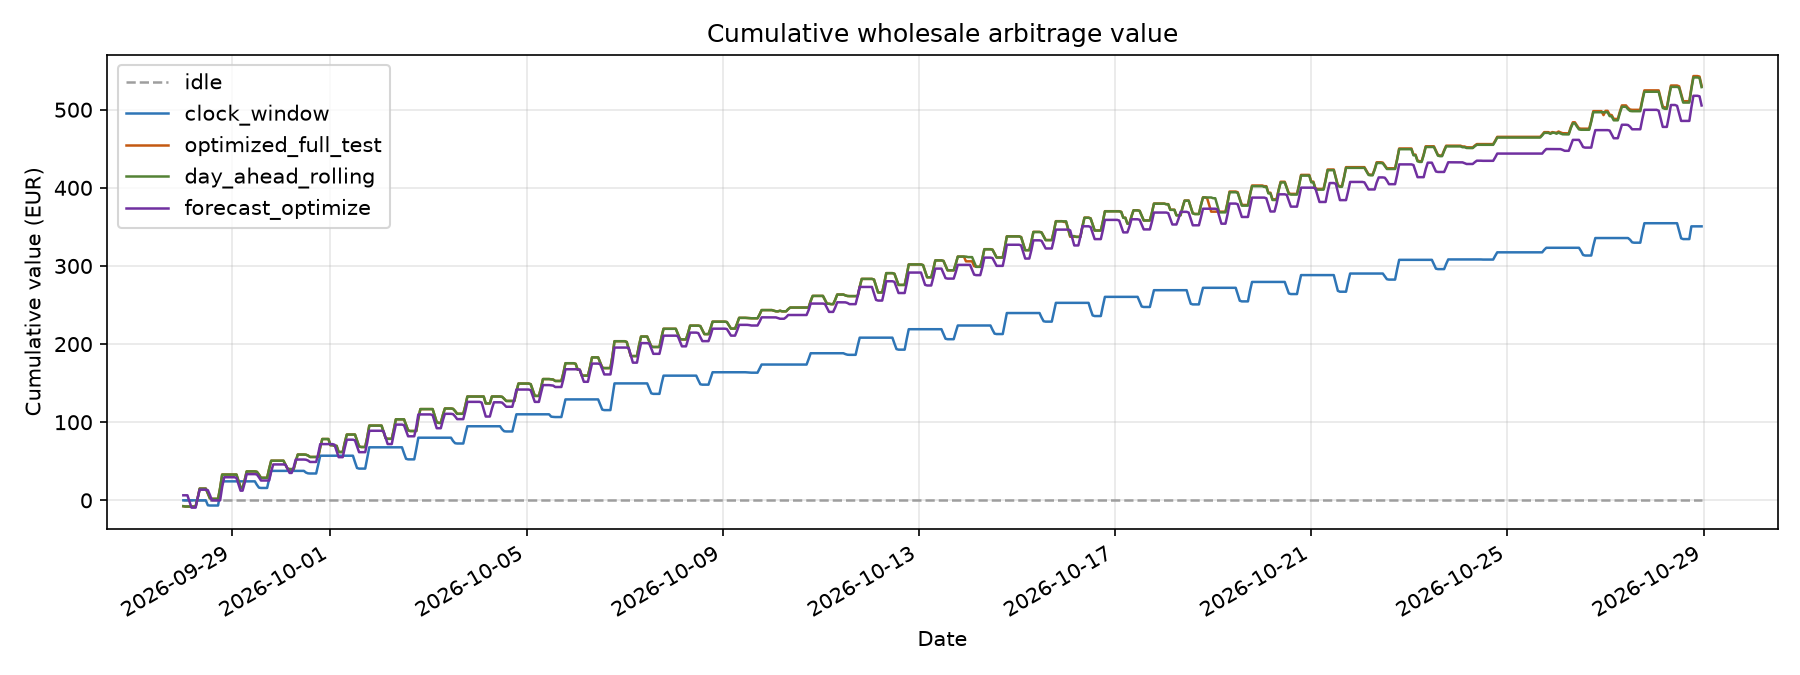

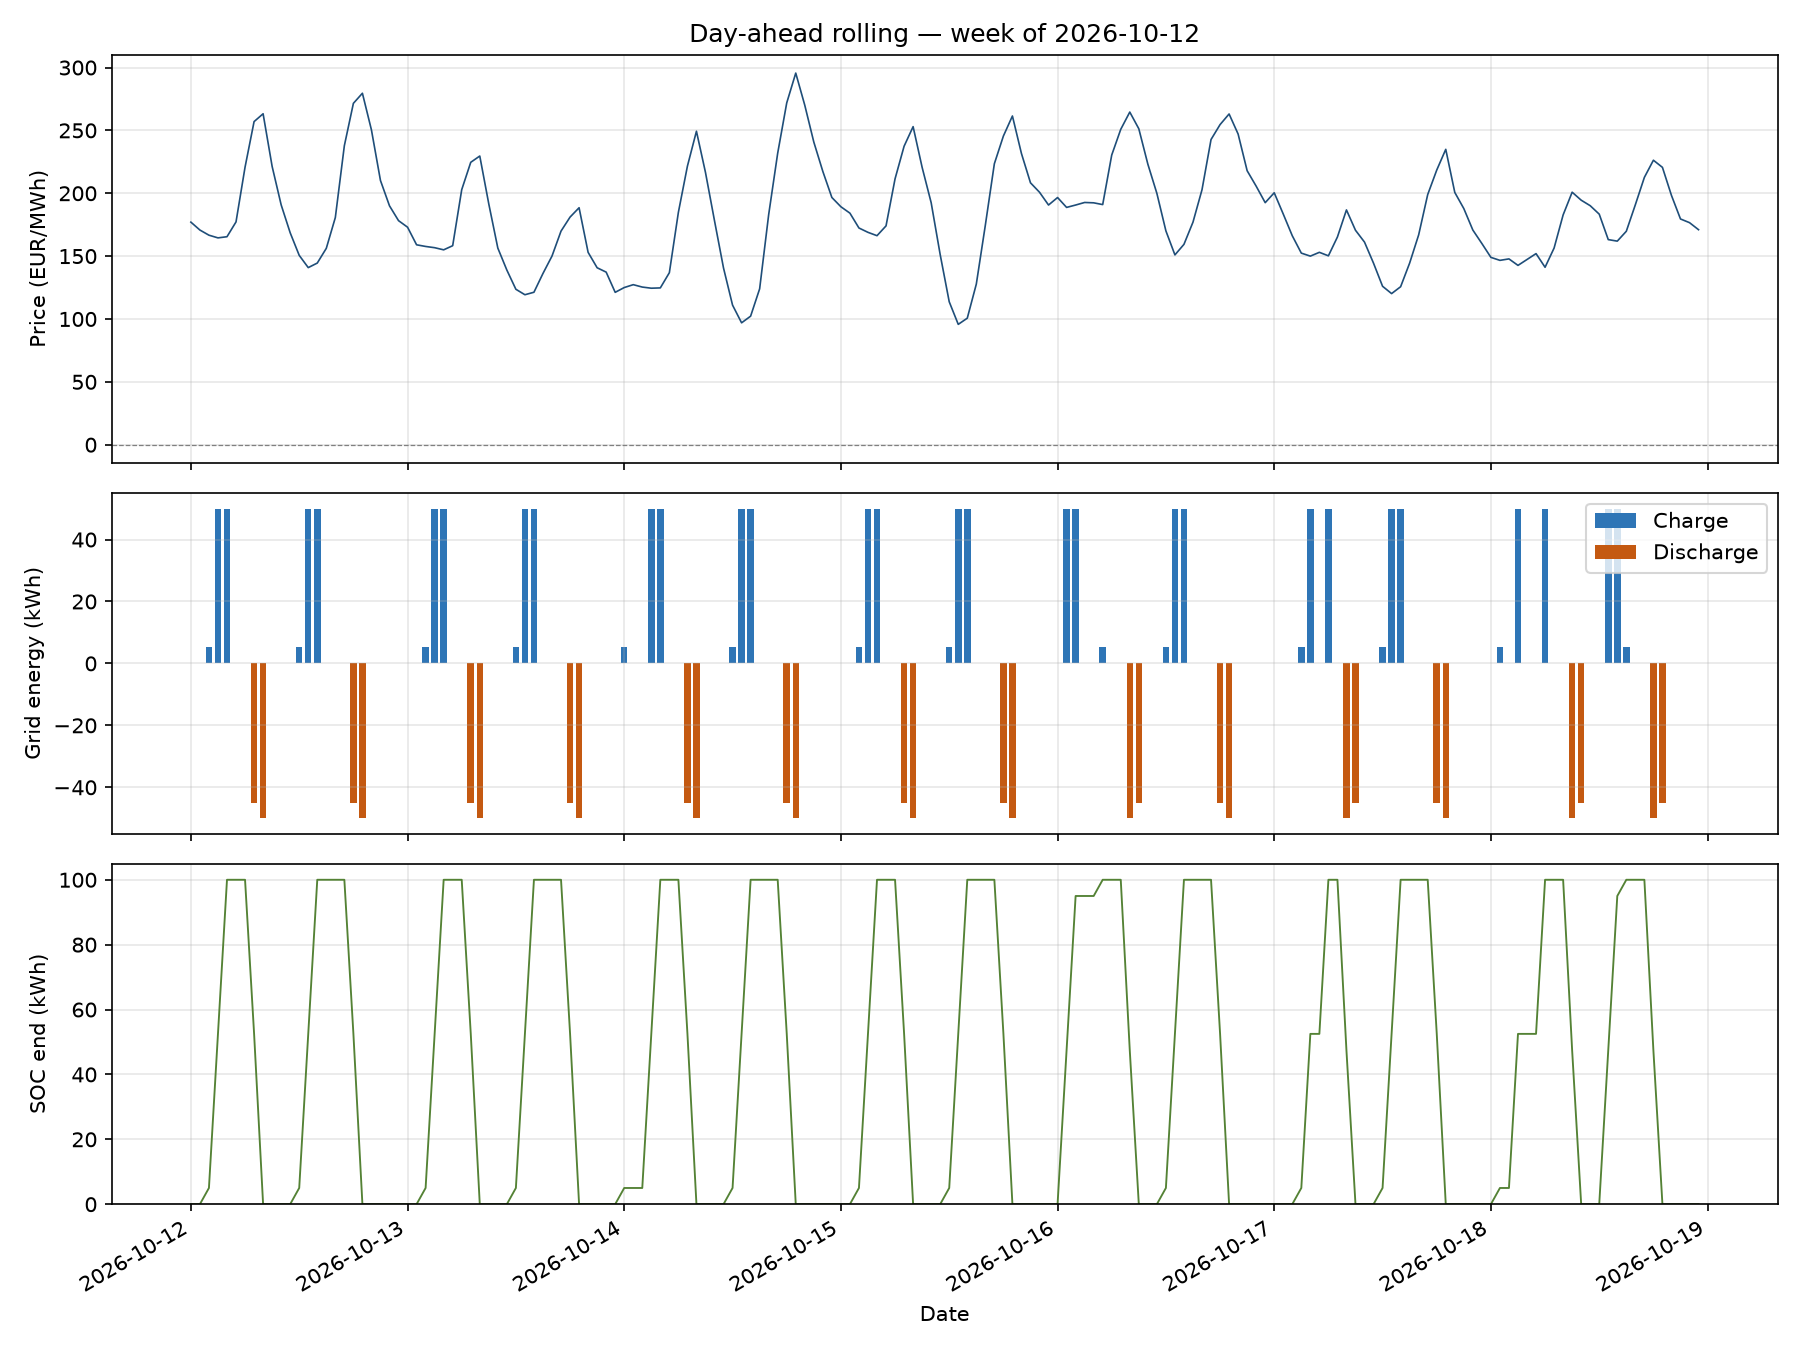

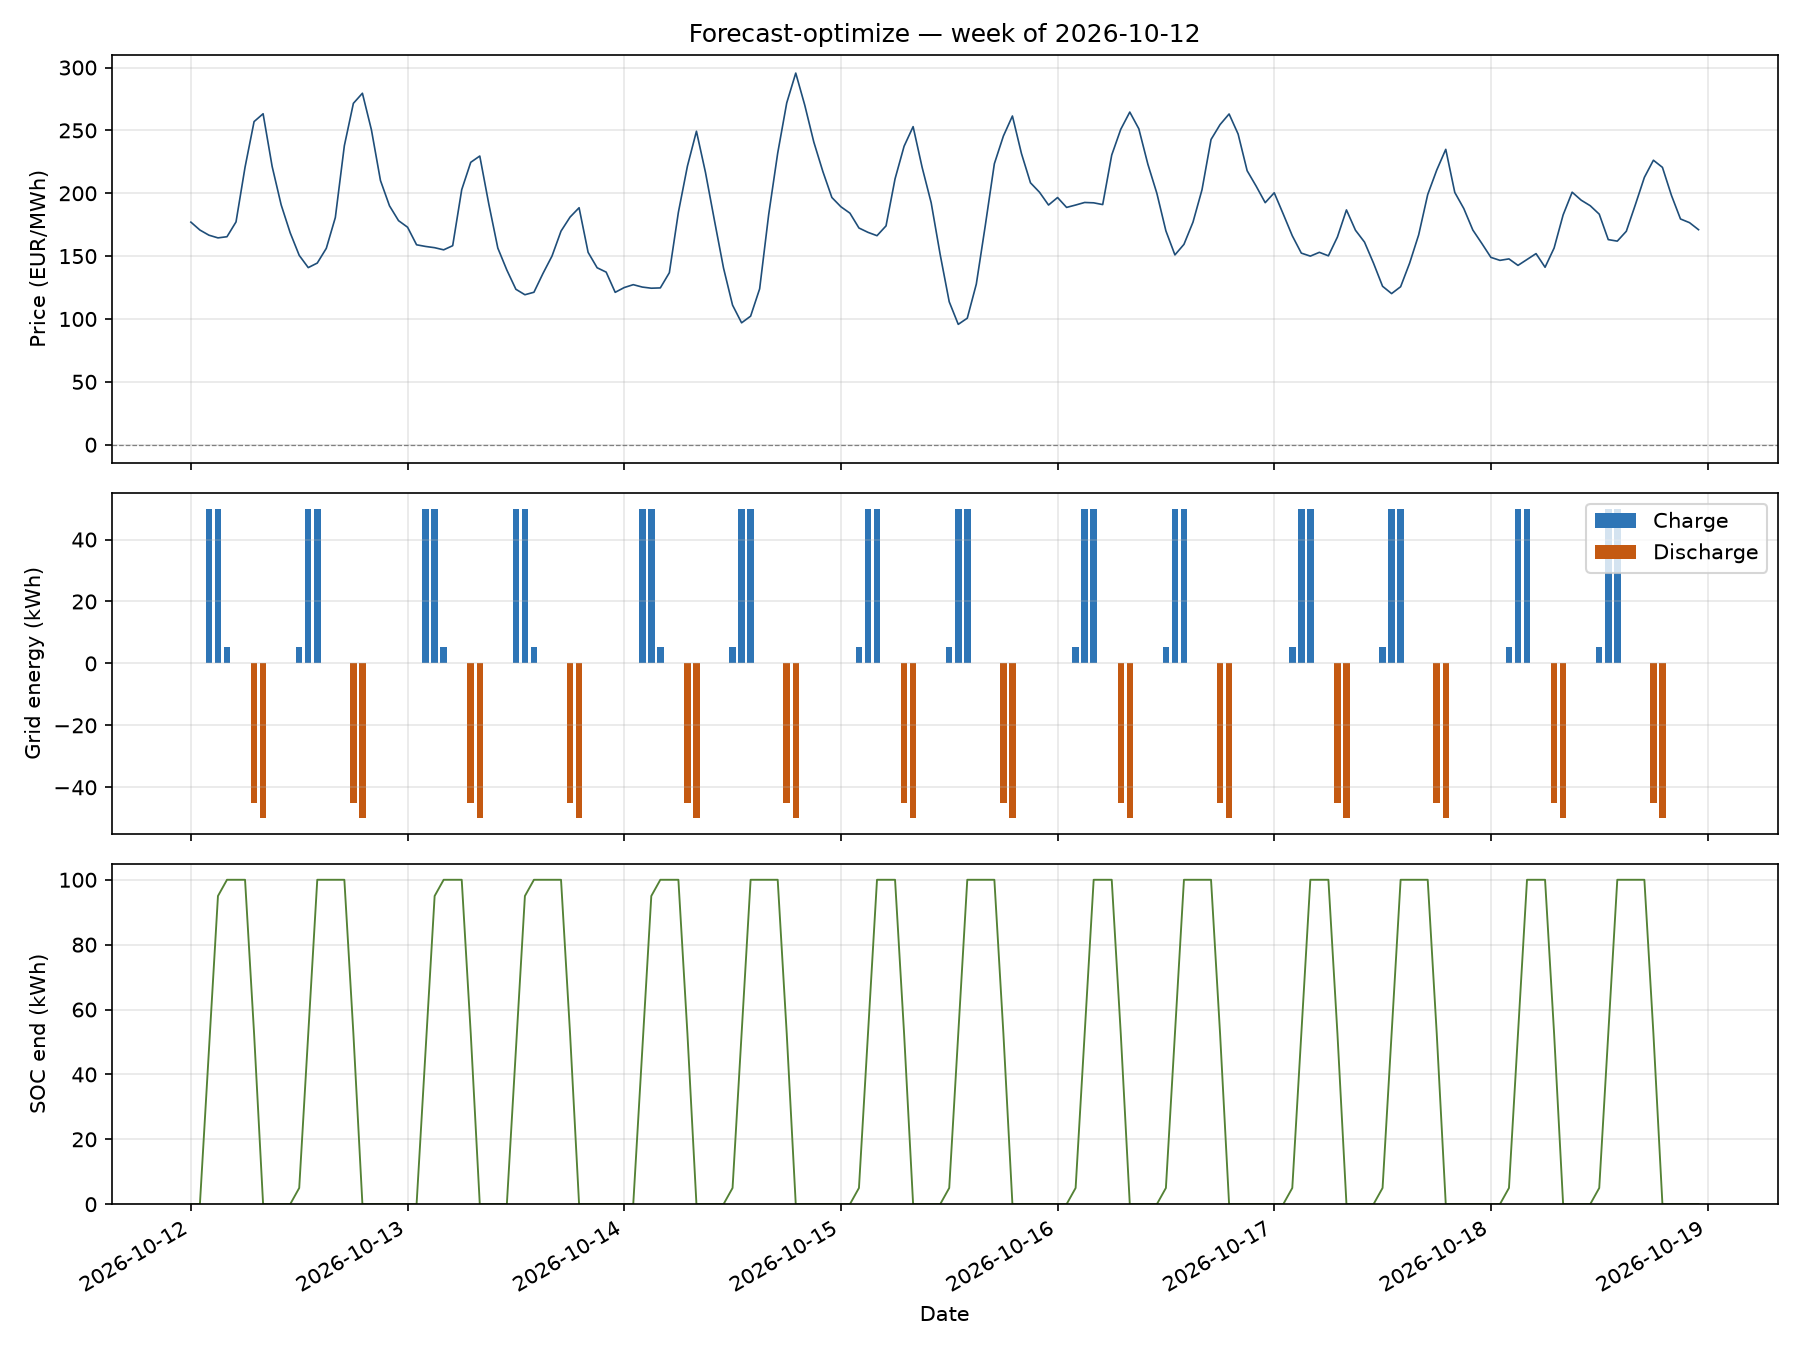

mean forecast MAE (EUR/kWh): 0.05108300499231951


,day,status,planned_obj_on_forecast,realized_arb,forecast_mae_eur_per_kwh,soc_end,n_history_rows
0,2026-09-28,optimal,36.1614,29.5552,0.0418,0.0000,744
1,2026-09-29,optimal,26.7510,16.4104,0.0252,0.0000,768
2,2026-09-30,optimal,22.9177,26.0188,0.0223,0.0000,792
3,2026-10-01,optimal,22.9350,17.0678,0.0416,0.0000,816
4,2026-10-02,optimal,21.5462,20.9264,0.0384,0.0000,840


In [9]:
from src.strategies import (
    day_ahead_rolling_strategy,
    forecast_optimize_strategy,
    holdout_split,
)

warm, test, holdout_meta = holdout_split(prices, frac=0.5)
display(pd.Series(holdout_meta))

idle_t = idle_strategy(test, batt)
rule_t = clock_window_strategy(test, batt)
opt_t = optimize_dispatch(test, batt)  # perfect foresight on TEST only
da_t = day_ahead_rolling_strategy(test, batt)
fc_t = forecast_optimize_strategy(test, batt, history=warm, lookback_days=7)

metrics_h = [
    evaluate_schedule(idle_t, batt, strategy_name="idle"),
    evaluate_schedule(rule_t, batt, strategy_name="clock_window"),
    evaluate_schedule(opt_t.schedule, batt, strategy_name="optimized_full_test"),
    evaluate_schedule(da_t, batt, strategy_name="day_ahead_rolling"),
    evaluate_schedule(fc_t, batt, strategy_name="forecast_optimize"),
]
table_h = comparison_table(metrics_h)
display(table_h)
table_h.to_csv(REPO / "reports" / "strategy_comparison_holdout.csv", index=False)

plot_strategy_arbitrage_comparison(table_h, fig_dir=fig_dir, filename="06_strategy_arbitrage_comparison.png")
plot_cumulative_arbitrage(
    {
        "idle": idle_t,
        "clock_window": rule_t,
        "optimized_full_test": opt_t.schedule,
        "day_ahead_rolling": da_t,
        "forecast_optimize": fc_t,
    },
    fig_dir=fig_dir,
    filename="09_cumulative_arbitrage.png",
)

mid = pd.Timestamp(test["timestamp"].iloc[len(test) // 2])
zoom_start = mid.normalize() - pd.Timedelta(days=int(mid.day_of_week))
zoom_end = zoom_start + pd.Timedelta(days=7)
plot_dispatch_zoom(
    da_t, start=zoom_start, end=zoom_end, fig_dir=fig_dir,
    filename="11_day_ahead_rolling_zoom.png",
    title=f"Day-ahead rolling — week of {zoom_start.date()}",
)
plot_dispatch_zoom(
    fc_t, start=zoom_start, end=zoom_end, fig_dir=fig_dir,
    filename="12_forecast_optimize_zoom.png",
    title=f"Forecast-optimize — week of {zoom_start.date()}",
)

for name in [
    "06_strategy_arbitrage_comparison.png",
    "09_cumulative_arbitrage.png",
    "11_day_ahead_rolling_zoom.png",
    "12_forecast_optimize_zoom.png",
]:
    display(Image(filename=str(fig_dir / name)))

if "day_meta" in fc_t.attrs:
    dm = pd.DataFrame(fc_t.attrs["day_meta"])
    print("mean forecast MAE (EUR/kWh):", dm["forecast_mae_eur_per_kwh"].mean())
    display(dm.head())

### Interpretation

- **optimized_full_test**: oracle over the whole test window (still unrealistic long-range foresight).
- **day_ahead_rolling**: realistic *if* day-ahead prices are known when planning the next day (true after DA auction).
- **forecast_optimize**: more realistic *before* prices are known; quality tracks forecast error.
- Gap oracle → forecast ≈ cost of not knowing future prices (with this naive forecast).